# Financial Transaction Fraud Detector
## Notebook 03 - Feature Engineering & Threat Model

**Owner:** Mohamed Rafat  
**Role:** Feature Engineering & Threat Model  
**Course / University:** AI in Cybersecurity, Sohag University  
**Date:** 2026-11-24

**Goal.** Describe how attackers operate and turn that into features the model can use, including receiver history computed without looking into the future.

**Inputs:** `data/processed/clean.parquet`, `src/features.py`

**Outputs:** `data/processed/features.parquet`, `reports/figures/03_*.png`

Run the notebooks in order 01, 02, 03, 04a, 04b, 05; each one reads the files saved by the previous one.

## 1. Threat model: how the attacker operates

Before choosing features, we describe the attack we want to stop.

| Item | Description |
|---|---|
| **Attacker** | A criminal who gains control of a customer's mobile-money account (stolen PIN or SIM, phishing, malware). |
| **Goal** | Move the victim's money out and turn it into cash before anyone notices. |
| **Assets at risk** | The customer's balance and the bank's trust. |
| **Attacker's limits** | Cannot withdraw directly from the victim's account without being traced, so the money must pass through other accounts. |

**The attack chain in PaySim:**

```
 1. Account takeover        2. TRANSFER               3. Mule account            4. CASH_OUT
 +------------------+      +------------------+      +------------------+      +------------------+
 | Victim's account | ---> | Money sent to    | ---> | Receives money,  | ---> | Money withdrawn  |
 | is compromised   |      | another account  |      | often new        |      | as cash          |
 +------------------+      +------------------+      +------------------+      +------------------+
```

**Why mule accounts matter.** A *money mule* is an account used only to receive stolen money and pass it on.
Mule accounts are often **new** (no earlier history) or show **unusual bursts** of incoming money. A bank
cannot see the criminal, but it can see the **receiving account's history**. That is the idea behind our
receiver-history features.

**What the attacker can change** (tested later in notebook 04b): the amount (split it into pieces), the
hour (act in the daytime), and the receiver (use an older account instead of a new one).

## 2. Setup
All feature code lives in `src/features.py`, so the **app uses exactly the same code** as training.
In this notebook we explain each function and show its effect on example rows.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import data, plotstyle

plotstyle.apply()
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

In [2]:
from src import features as F

df = data.load_clean()
df["type"] = df["type"].astype(str)
print(f"{len(df):,} rows loaded (all types; receiver history needs all of them)")

6,362,620 rows loaded (all types; receiver history needs all of them)


## 3. What the model is NOT allowed to see

| Column | Why it is excluded |
|---|---|
| `isFraud` | It is the answer we want to predict (the target). |
| `isFlaggedFraud` | The simulator's own rule; we keep it only as a baseline to beat. |
| `nameOrig`, `nameDest` | Raw IDs carry no meaning and would let the model memorize accounts. We use them only to compute receiver history. |

## 4. Group 1: Basic features

These describe the transaction itself:

- `is_transfer`: 1 for TRANSFER, 0 for CASH_OUT
- `amount` and `log_amount` (the log makes huge and small amounts comparable)
- `hour` = `step % 24` (hour of day)
- `is_round_amount`: the amount is a multiple of 1,000
- `is_near_max_amount`: the amount is at least 99% of 10,000,000, the largest fraud amount in the data

We also compute `day` = `step // 24` for analysis, but **the models do not use it**: with a time-based
split the test days never appear in training, so the model would learn the calendar instead of fraud.

In [3]:
fraud_max = df.loc[df["isFraud"] == 1, "amount"].max()
assert fraud_max == F.FRAUD_MAX_AMOUNT, "FRAUD_MAX_AMOUNT in src/features.py must match the data"
print(f"Largest fraud amount in the data: {fraud_max:,.0f} (matches the constant used in src/features.py)")

examples = df[df["type"].isin(data.SCORED_TYPES)].groupby("isFraud").head(3)
basic = F.basic_features(examples)
pd.concat([examples[["step", "type", "amount", "isFraud"]], basic.drop(columns=["amount"])], axis=1)

Largest fraud amount in the data: 10,000,000 (matches the constant used in src/features.py)


,step,type,amount,isFraud,is_transfer,log_amount,hour,day,is_round_amount,is_near_max_amount
2,1,TRANSFER,181.00,1,1,5.20,1,0,0,0
3,1,CASH_OUT,181.00,1,0,5.20,1,0,0,0
15,1,CASH_OUT,"229,133.94",0,0,12.34,1,0,0,0
19,1,TRANSFER,"215,310.30",0,1,12.28,1,0,0,0
24,1,TRANSFER,"311,685.89",0,1,12.65,1,0,0,0
251,1,TRANSFER,"2,806.00",1,1,7.94,1,0,0,0


## 5. Group 2: Receiver history (the money-mule signal)

For every transaction we look at the **receiving account** and ask: what did this account receive **before**?

- `recv_count_before`: number of transactions it received before
- `recv_total_before`: total amount it received before
- `recv_is_new`: 1 if it never received anything before
- `recv_hours_since_last`: hours since its last incoming transaction (744 = never, the length of the data)

**The leakage rule.** We use only transactions from **strictly earlier hours** (`step` smaller than the
current one). Transactions in the same hour and anything in the future are never counted, because a bank
deciding on a transaction cannot know what happens later.

### 5.1 A small worked example
Account `C_MULE` receives money four times. Look at the two rows in the same hour (step 5): neither sees the other.

In [4]:
toy = pd.DataFrame({
    "step":     [1,        3,        5,        5,        9,         9],
    "type":     ["TRANSFER", "TRANSFER", "TRANSFER", "CASH_OUT", "TRANSFER", "TRANSFER"],
    "amount":   [100.0,    250.0,    400.0,    50.0,     1000.0,    70.0],
    "nameDest": ["C_MULE", "C_MULE", "C_MULE", "C_MULE", "C_NEW",   "C_MULE"],
})
pd.concat([toy, F.receiver_history(toy)], axis=1)

,step,type,amount,nameDest,recv_count_before,recv_total_before,recv_is_new,recv_hours_since_last
0,1,TRANSFER,100.00,C_MULE,0.00,0.00,1,744.00
1,3,TRANSFER,250.00,C_MULE,1.00,100.00,0,2.00
2,5,TRANSFER,400.00,C_MULE,2.00,350.00,0,2.00
3,5,CASH_OUT,50.00,C_MULE,2.00,350.00,0,2.00
4,9,TRANSFER,"1,000.00",C_NEW,0.00,0.00,1,744.00
5,9,TRANSFER,70.00,C_MULE,4.00,800.00,0,4.00


Reading the table:
- Step 1: `C_MULE` has no history, so it is **new** and `hours_since_last` is the cap (744).
- Step 3: it received one transfer (100) two hours earlier.
- Step 5 (two rows): both see only steps 1 and 3 (count 2, total 350). The other step-5 row is **not** counted.
- Step 9: `C_MULE` now has 4 earlier transfers (total 800), last one 4 hours ago. `C_NEW` is new.

### 5.2 Proof of no future leakage on the real data
If a feature used the future, deleting future rows would change it. We compute the features on the full data,
then again using **only the first 150 hours**, and check that the values for those hours are identical.
We also shuffle the row order to show the result does not depend on how the file is sorted.

In [5]:
full_hist = F.receiver_history(df)

cut = 150
early = df[df["step"] <= cut]
early_hist = F.receiver_history(early)
same = early_hist.equals(full_hist.loc[early.index])
print(f"Rows in the first {cut} hours: {len(early):,}")
print(f"Features identical with and without future rows: {same}")

shuffled = early.sample(frac=1.0, random_state=0)
diff = (F.receiver_history(shuffled).sort_index() - early_hist.sort_index()).abs().max()
same_shuffled = bool((diff < 1e-6).all())
print(f"Features identical after shuffling the rows: {same_shuffled}")
print(f"(largest difference: {diff.max():.1e}, only floating-point rounding when adding amounts in another order)")
assert same and same_shuffled

Rows in the first 150 hours: 1,511,368
Features identical with and without future rows: True


Features identical after shuffling the rows: True
(largest difference: 7.5e-09, only floating-point rounding when adding amounts in another order)


## 6. Groups 3 and 4: Balance features

- **Pre-transaction (group P)**: `oldbalanceOrg`, `oldbalanceDest` and `amount_to_balance` = amount / sender balance.
  A bank knows these **before** it approves a transaction. The division is safe: a zero balance is treated as 1.
- **Post-transaction (group L)**: `newbalanceOrig`, `newbalanceDest` and the balance errors
  `errorOrig = oldbalanceOrg - amount - newbalanceOrig` and `errorDest = oldbalanceDest + amount - newbalanceDest`.
  These are known only **after** the transaction and, as notebook 02 showed, they are distorted by how the
  simulator cancelled fraud. Model L uses them only to demonstrate the leakage problem.

In [6]:
bal = F.balance_features(examples)
pd.concat([examples[["amount", "isFraud"]], bal], axis=1)

,amount,isFraud,oldbalanceOrg,oldbalanceDest,amount_to_balance,newbalanceOrig,newbalanceDest,errorOrig,errorDest
2,181.00,1,181.00,0.00,1.00,0.00,0.00,0.00,181.00
3,181.00,1,181.00,"21,182.00",1.00,0.00,0.00,0.00,"21,363.00"
15,"229,133.94",0,"15,325.00","5,083.00",14.95,0.00,"51,513.44","-213,808.94","182,703.50"
19,"215,310.30",0,705.00,"22,425.00",305.40,0.00,0.00,"-214,605.30","237,735.30"
24,"311,685.89",0,"10,835.00","6,267.00",28.77,0.00,"2,719,172.89","-300,850.89","-2,401,220.00"
251,"2,806.00",1,"2,806.00",0.00,1.00,0.00,0.00,0.00,"2,806.00"


## 7. Build all features and keep TRANSFER and CASH_OUT
Receiver history was computed above on **all** types; now we add the other groups and keep only the two types we model.

In [7]:
feats = F.build_features(df, history=full_hist)
feats = pd.concat([df[["row_id", "step", "type", "isFraud", "isFlaggedFraud"]], feats], axis=1)
feats = feats[feats["type"].isin(data.SCORED_TYPES)].reset_index(drop=True)
feats["type"] = feats["type"].astype("category")
print(f"Feature table: {len(feats):,} rows x {feats.shape[1]} columns")
print("Feature sets:")
for k, cols in F.FEATURE_SETS.items():
    print(f"  {k}: {len(cols)} features")

Feature table: 2,770,409 rows x 23 columns
Feature sets:
  R: 10 features
  P: 13 features
  L: 17 features


In [8]:
med_cols = ["amount", "recv_count_before", "recv_hours_since_last", "amount_to_balance"]
summary = feats.groupby("isFraud")[med_cols].median().T
summary.columns = ["Normal (median)", "Fraud (median)"]
summary.index = [F.FEATURE_LABELS[c] for c in med_cols]
summary

,Normal (median),Fraud (median)
Amount,"171,034.46","441,423.44"
Receiver: transfers received before,5.00,0.00
Receiver: hours since last incoming,21.00,744.00
Amount / sender balance,607.63,1.00


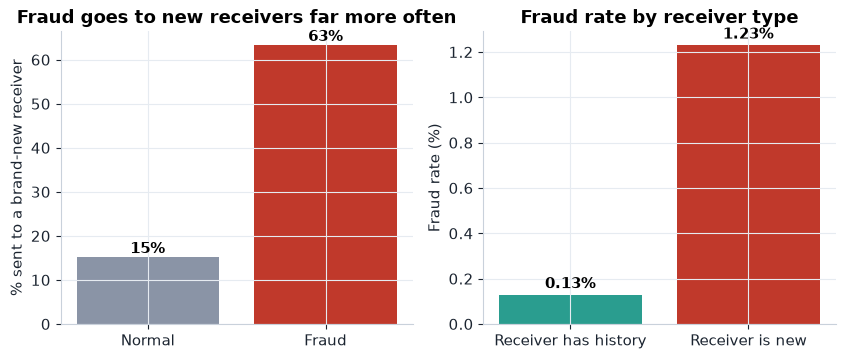

In [9]:
new_rate = feats.groupby("isFraud")["recv_is_new"].mean() * 100
fraud_rate_new = feats.groupby("recv_is_new")["isFraud"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].bar(["Normal", "Fraud"], new_rate.values, color=[plotstyle.GREY, plotstyle.RED])
axes[0].set_ylabel("% sent to a brand-new receiver")
axes[0].set_title("Fraud goes to new receivers far more often")
for i, v in enumerate(new_rate.values):
    axes[0].text(i, v + 1, f"{v:.0f}%", ha="center", fontweight="bold")
axes[1].bar(["Receiver has history", "Receiver is new"], fraud_rate_new.values, color=[plotstyle.TEAL, plotstyle.RED])
axes[1].set_ylabel("Fraud rate (%)")
axes[1].set_title("Fraud rate by receiver type")
for i, v in enumerate(fraud_rate_new.values):
    axes[1].text(i, v + 0.03, f"{v:.2f}%", ha="center", fontweight="bold")
plotstyle.save(fig, "03_new_receiver")
plt.show()

In [10]:
cols = ["row_id", "step", "type", "isFraud", "isFlaggedFraud"] + F.FEATURE_SETS["L"] + ["day"]
feats[cols].to_parquet(data.FEATURES_PARQUET, index=False)
print(f"Saved data/processed/features.parquet: {data.FEATURES_PARQUET.stat().st_size / 1e6:.0f} MB")

Saved data/processed/features.parquet: 160 MB


In [11]:
lift = fraud_rate_new[1] / fraud_rate_new[0]
data.write_findings("03_feature_engineering", [
    "Threat model: account takeover, then a TRANSFER to a mule account, then a CASH_OUT; the bank can watch the receiving account even when it cannot see the attacker.",
    f"We built {len(F.FEATURE_SETS['L'])} features in four groups: basic ({len(F.BASIC)}), receiver history ({len(F.RECEIVER)}), pre-transaction balances ({len(F.PRE)}) and post-transaction balances ({len(F.POST)}).",
    f"Receiver history uses only strictly earlier hours; recomputing it without future rows gave identical values for all {len(early):,} rows of the first {cut} hours.",
    f"{new_rate[1]:.0f}% of frauds go to a brand-new receiver versus {new_rate[0]:.0f}% of normal transfers; transactions to new receivers are {lift:.1f}x more likely to be fraud.",
    "IDs, isFraud and isFlaggedFraud are never model inputs; the calendar day is not used either, because the time-based split would turn it into a shortcut.",
    f"Saved {len(feats):,} TRANSFER and CASH_OUT rows to features.parquet.",
])
print("Findings saved.")

Findings saved.


## Key findings

- Threat model: account takeover, then a TRANSFER to a mule account, then a CASH_OUT; the bank can watch the receiving account even when it cannot see the attacker.
- We built 17 features in four groups: basic (6), receiver history (4), pre-transaction balances (3) and post-transaction balances (4).
- Receiver history uses only strictly earlier hours; recomputing it without future rows gave identical values for all 1,511,368 rows of the first 150 hours.
- 63% of frauds go to a brand-new receiver versus 15% of normal transfers; transactions to new receivers are 9.6x more likely to be fraud.
- IDs, isFraud and isFlaggedFraud are never model inputs; the calendar day is not used either, because the time-based split would turn it into a shortcut.
- Saved 2,770,409 TRANSFER and CASH_OUT rows to features.parquet.